# 1. Super-resolution ×4 with a drift-generator prior (pixel_B_sota): CSGM vs IADrift

**Question.** IAGAN (Hussein et al., 2020) showed that a GAN prior for inverse problems gets much better if, after
inverting the generator (CSGM, Bora et al., 2017), one also adapts the generator's *weights* to the measurement.
Does this transfer when the prior is a **drifting model** instead of a GAN? We test it with one pretrained model, `pixel_B_sota`, on
super-resolution ×4 of ImageNet images; the conclusions are about this generator.

**This notebook** contains the main, **pre-registered test results** (100 held-out test images). Each section goes
*math → code → results*:

| Section | Content |
|---|---|
| 2 | The inverse problem and the measurement operator $A$ |
| 3 | The prior: the drift generator $G_\theta$ |
| 4 | Method 1: CSGM (optimize the generator's input) |
| 5 | Method 2: IADrift (also adapt the generator's weights, as in IAGAN) |
| 6 | Back-projection (make any reconstruction consistent with $y$) |
| 7 | Metrics |
| 8 | Protocol and statistics |
| 9 | **Results**: tables (PSNR, LPIPS) and figures |
| 10 | Summary |

The optimizations themselves (600 runs, about 10 GPU-hours on one RTX A4000) were run with the scripts in `scripts/`.
This notebook shows their code and reads their precomputed per-image results from `results/`
(made by `scripts/analysis/export_results.py`), so it runs on a CPU in under a minute.

## Setup

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # the notebook itself never needs a GPU

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display
from jax.scipy.sparse.linalg import cg
from scipy import stats

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = REPO / "results"

sample = json.loads((RESULTS / "test_sample.json").read_text())          # the 100 test images
metrics = json.loads((RESULTS / "test_metrics.json").read_text())        # per-image metrics of every method
primary_saved = json.loads((RESULTS / "primary_iadrift.json").read_text())
traces = np.load(RESULTS / "iadrift_traces.npz")
_ex = np.load(RESULTS / "examples_test.npz")
images = [s["image_index"] for s in sample]
examples = [{k.split("|", 1)[1]: _ex[k].astype(np.float32) for k in _ex.files if k.startswith(f"{n}|")}
            for n in range(len(_ex["image_index"]))]
print(f"{len(images)} test images, {len(next(iter(metrics.values()))) - 1} methods with per-image metrics, "
      f"{len(examples)} example images")

100 test images, 14 methods with per-image metrics, 4 example images


## 2. The inverse problem

An image $x^\star \in [-1,1]^{256\times256\times3}$ is observed only through a low-resolution measurement

$$
y = A\,x^\star \in \mathbb{R}^{64\times64\times3},
$$

where $A$ is **antialiased bicubic downsampling by 4** (a fixed linear map). Recovering $x^\star$ from $y$ is ill-posed:

- $A$ maps $196{,}608$ unknowns to $12{,}288$ measurements, so its **null space** has dimension at least
  $184{,}320$ (exactly that if $A$ has full row rank): infinitely many images give exactly the same $y$.
- In frequency terms, a $64\times64$ image holds frequencies only up to the LR Nyquist limit
  $f_{\text{LR}} = 0.125$ cycles/pixel (of the HR grid). Content above $f_{\text{LR}}$ (edges, texture) is mostly not
  measured and must come from a **prior**. The bicubic kernel is not an ideal low-pass filter, so this boundary is soft.

The baseline is **bicubic upsampling**, which adds almost nothing above $f_{\text{LR}}$.

max |A(HR) - y| = 0.00047010183334350586 (float16 storage of the example arrays limits this to ~1e-3)


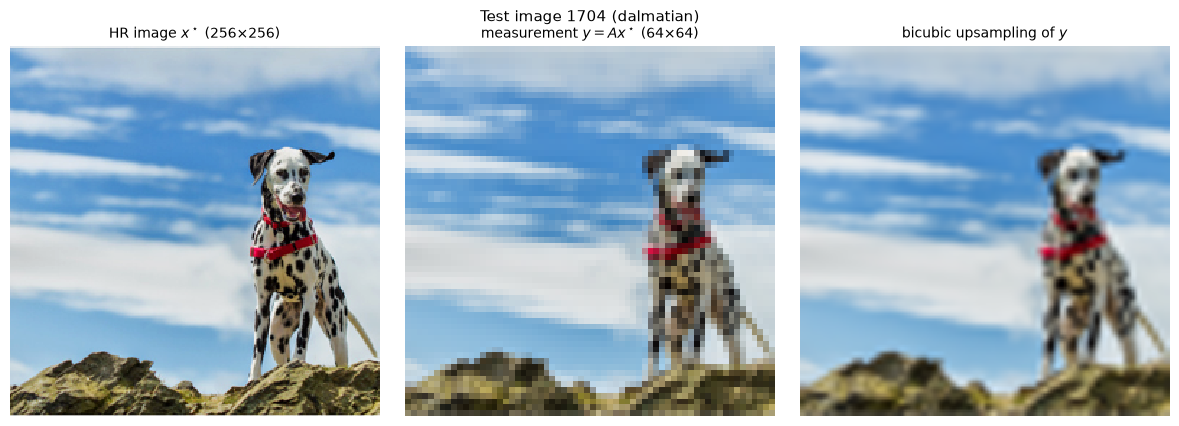

In [2]:
def A_sr4(x):
    """Measurement operator: antialiased bicubic 256 -> 64. x: [batch, 256, 256, 3] -> [batch, 64, 64, 3]."""
    return jax.image.resize(x.astype(jnp.float32), (x.shape[0], 64, 64, 3), method="cubic", antialias=True)


def bicubic_up(y):
    """Baseline: bicubic upsampling 64 -> 256 (no antialiasing needed when upsampling). y: [64, 64, 3]."""
    return np.asarray(jax.image.resize(jnp.asarray(y, jnp.float32), (256, 256, 3), method="cubic", antialias=False))


# Check on the first test image: the stored measurement is A applied to the stored HR image.
ex = examples[0]
print("max |A(HR) - y| =", float(jnp.abs(A_sr4(jnp.asarray(ex["hr"])[None])[0] - ex["lr"]).max()),
      "(float16 storage of the example arrays limits this to ~1e-3)")

show = lambda x: (np.clip(x, -1, 1) + 1) / 2
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, (title, x) in zip(axes, [("HR image $x^\\star$ (256×256)", ex["hr"]),
                                 ("measurement $y = Ax^\\star$ (64×64)", ex["lr"]),
                                 ("bicubic upsampling of $y$", ex["bicubic"])]):
    ax.imshow(show(x), interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.suptitle(f"Test image {images[0]} ({sample[0]['true_class']})", fontsize=11)
plt.tight_layout()
plt.show()

## 3. The prior: a drifting model

We use the pretrained class-conditional generator `pixel_B_sota` from *Generative Modeling via Drifting*
(Deng et al., 2026, arXiv:2602.04770): a DiT-style B/16 transformer (134M parameters) that maps noise to an image in **one forward pass**:

$$
x = G_\theta(\varepsilon;\, z, c), \qquad
\varepsilon \in \mathbb{R}^{256\times256\times3},\ \varepsilon \sim \mathcal N(0, I), \quad
z \in \{0,\dots,63\}^{32}, \quad c \in \{0,\dots,999\}.
$$

- $\varepsilon$ (**pixel noise**) is cut into $16\times16$ patches, one token each (256 tokens). This patch grid is the
  origin of the **16-pixel tile seams** measured below.
- $z$ (**32 discrete noise labels**, called style labels $s$ in the report) and the class $c$ are embedded, summed into one conditioning vector, and modulate
  every transformer block (AdaLN). We always use the true class $c$ (oracle label) unless stated, and guidance scale 1.
- "Drift" refers to how it was **trained** (a drifting field in feature space); at inference it is a plain generator,
  which is what CSGM and IAGAN need.

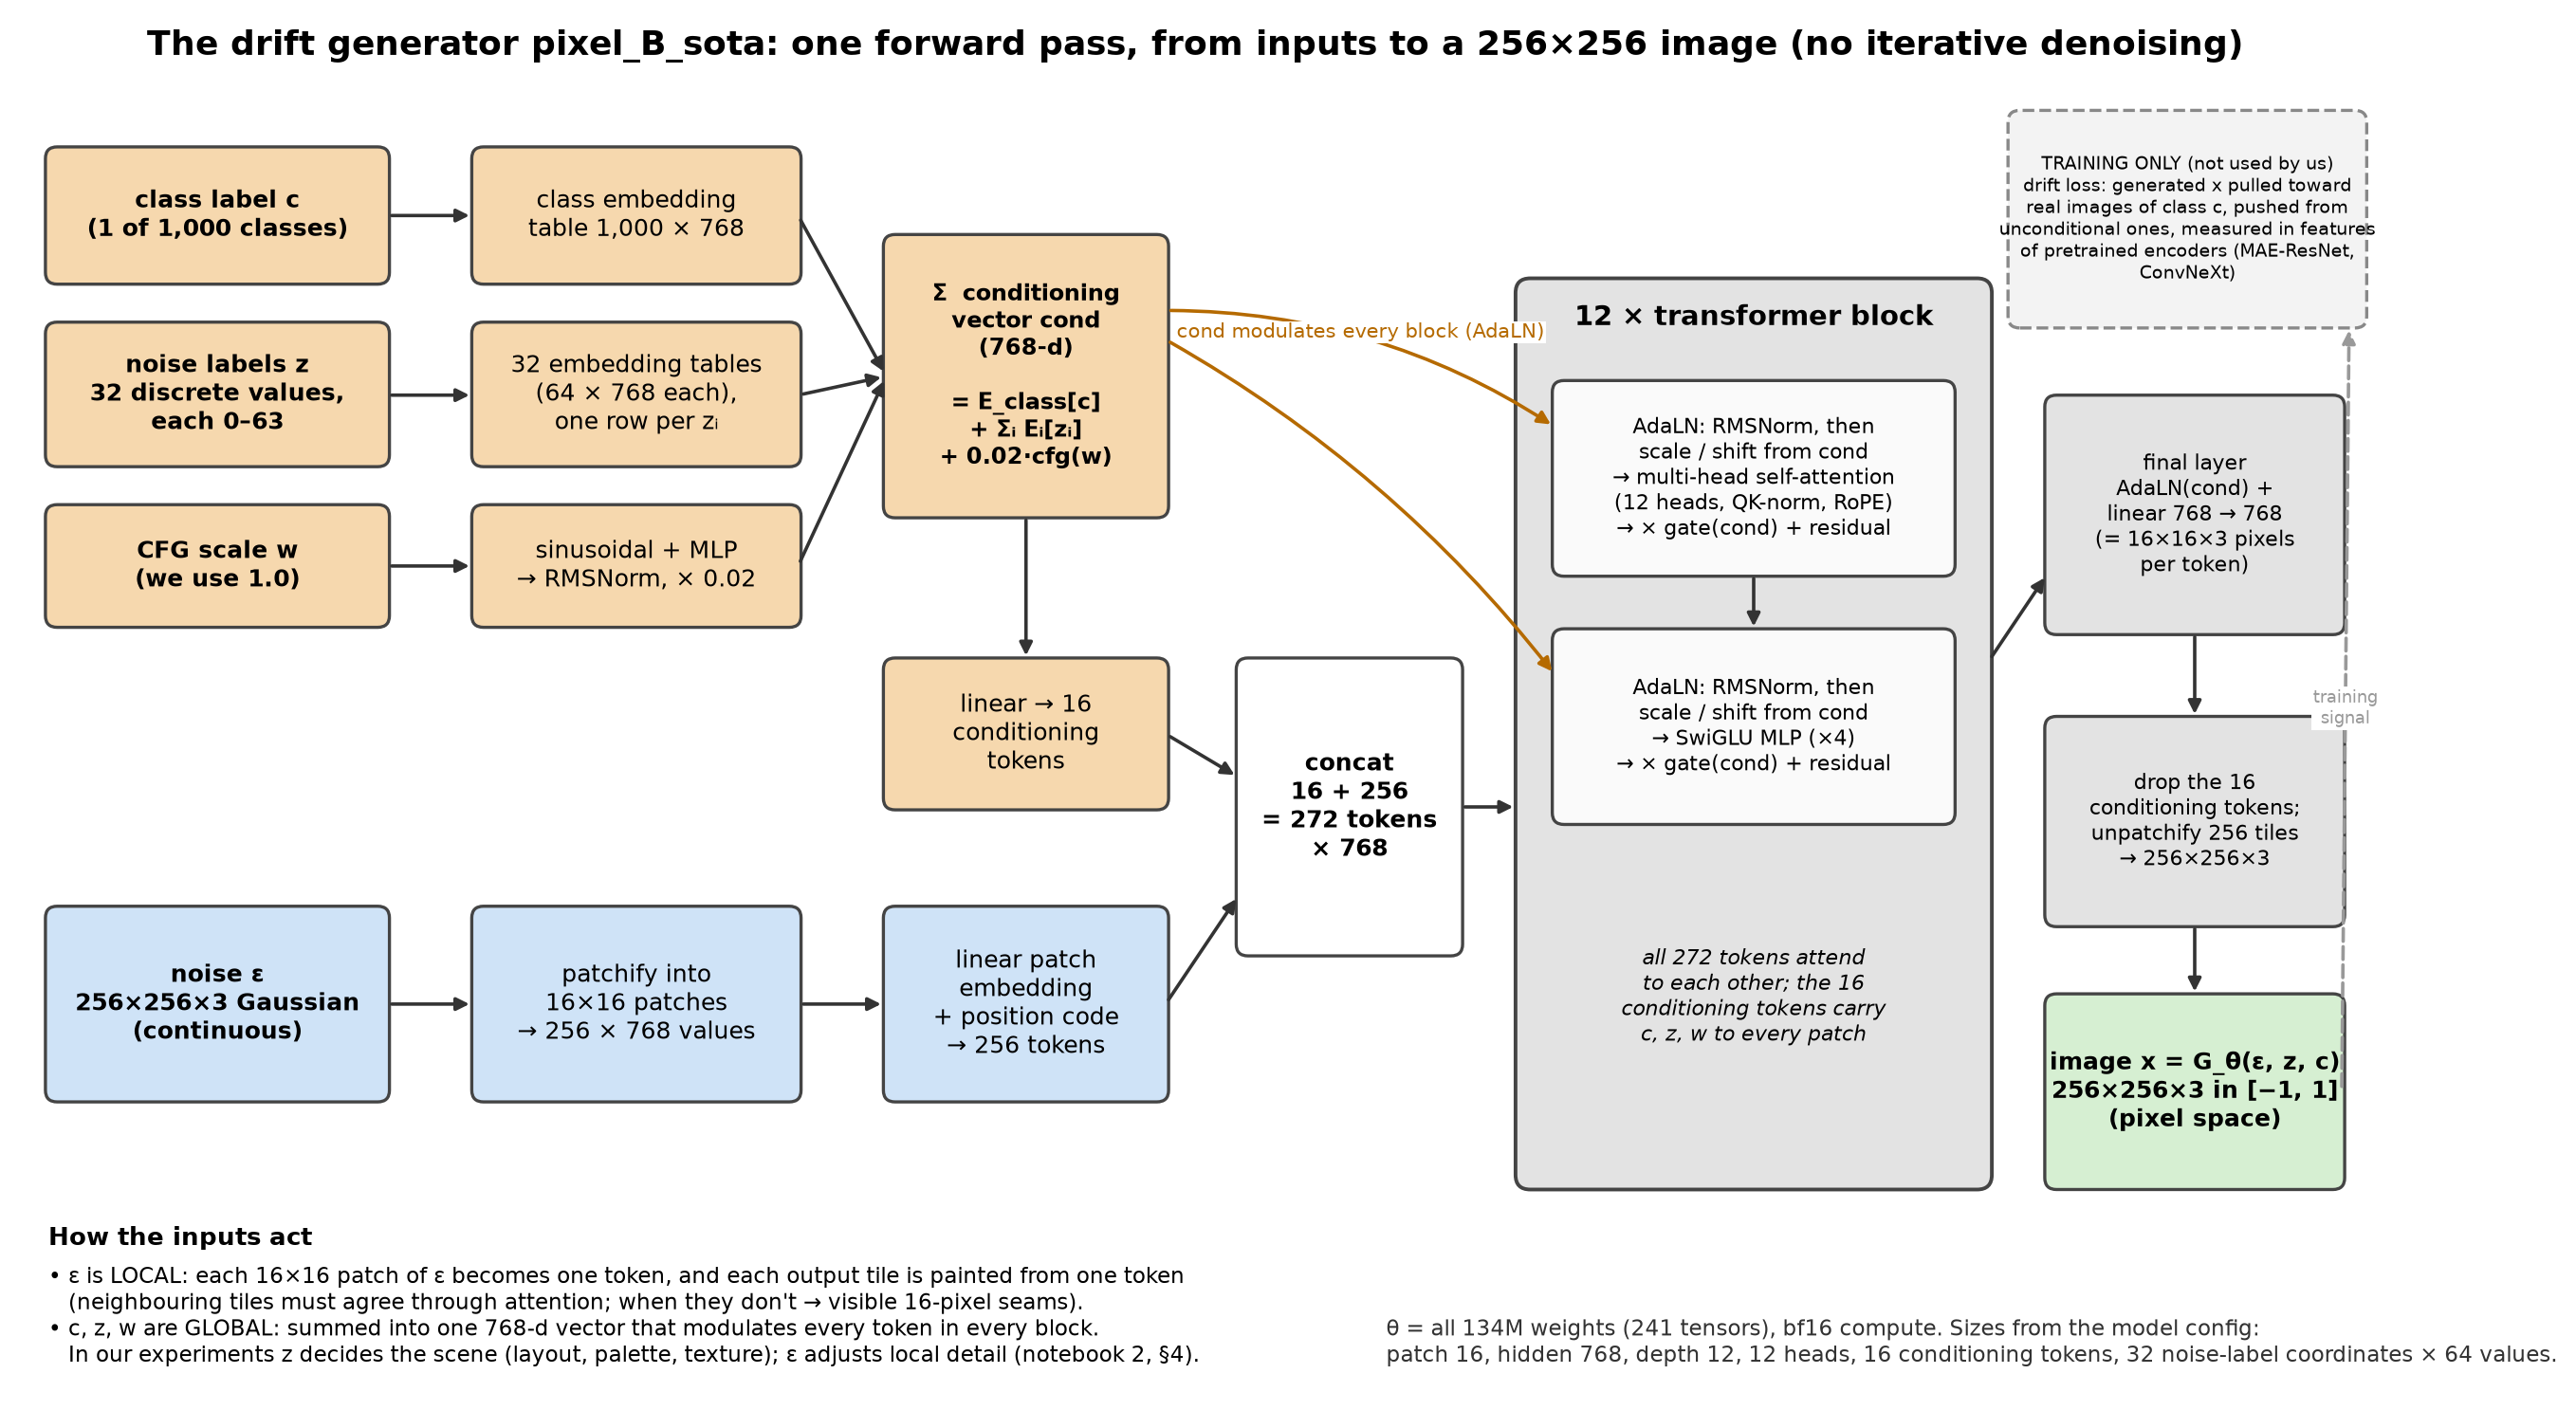

In [3]:
display(Image(filename=str(REPO / "figures" / "model_diagram_generator.png"), width=900))


def generate(model, theta, eps, label, noise_labels):
    """x = G_theta(eps; z, c) with guidance scale 1 (upstream models/generator.py API). Returns [1, 256, 256, 3]."""
    condition = model.apply({"params": theta}, jnp.asarray(label, jnp.int32).reshape(1), 1.0, noise_labels,
                            method=model.c_cfg_noise_to_cond)
    return model.apply({"params": theta}, eps, condition, True, method=model.generate_image).astype(jnp.float32)

## 4. Method 1: CSGM (freeze the generator, optimize its input)

CSGM searches the generator's input for the image that best explains the measurement:

$$
\hat\varepsilon = \arg\min_{\varepsilon}\ \mathcal L(\varepsilon), \qquad
\mathcal L(\varepsilon) = \big\| y - A\,G_{\theta_0}(\varepsilon;\, z, c) \big\|_2^2, \qquad
\hat x_{\text{CSGM}} = G_{\theta_0}(\hat\varepsilon;\, z, c).
$$

- $\theta_0$: pretrained weights, frozen. The noise labels $z$ are discrete, so they are drawn at random and kept fixed.
- **Adam**, learning rate 0.02, **5,000 steps**, no regularizer (chosen on a 100-image *development* sweep, `scripts/dev/run_csgm_settings_sweep.py`).
- **2 restarts** (random $\varepsilon$ and $z$); we keep the restart with the **lowest final LR loss** $\mathcal L$.
  The HR image is never used for any choice: it is used only for scoring.

In [4]:
import optax

CSGM = {"learning_rate": 0.02, "num_steps": 5_000, "num_restarts": 2}
SWEEP_SEED = 2026


def initialize(model, image_index, restart):
    """Random start (eps, z) per image and restart; independent of the class label."""
    key = jax.random.fold_in(jax.random.fold_in(jax.random.PRNGKey(SWEEP_SEED), image_index), restart)
    key_eps, key_z = jax.random.split(key)
    eps = jax.random.normal(key_eps, (1, 256, 256, 3), dtype=jnp.float32)
    noise_labels = jax.random.randint(key_z, (1, model.noise_coords), 0, model.noise_classes, dtype=jnp.int32)
    return eps, noise_labels


def csgm(model, theta0, y, label, image_index):
    """CSGM for one image: run every restart, keep the one with the lowest final LR loss. y: [1, 64, 64, 3]."""
    optimizer = optax.adam(CSGM["learning_rate"])
    loss_fn = lambda eps, z: jnp.sum((A_sr4(generate(model, theta0, eps, label, z)) - y) ** 2)

    @jax.jit
    def step(eps, state, z):
        loss, grad = jax.value_and_grad(loss_fn)(eps, z)
        updates, state = optimizer.update(grad, state, eps)
        return optax.apply_updates(eps, updates), state, loss

    runs = []
    for restart in range(CSGM["num_restarts"]):
        eps, z = initialize(model, image_index, restart)
        state = optimizer.init(eps)
        for _ in range(CSGM["num_steps"]):
            eps, state, _ = step(eps, state, z)
        runs.append((float(loss_fn(eps, z)), restart, eps, z))
    final_loss, restart, eps, z = min(runs, key=lambda r: (r[0], r[1]))  # LR loss only, never HR
    return np.asarray(generate(model, theta0, eps, label, z))[0], eps, z

## 5. Method 2: IADrift (image-adaptive drift generator, as in IAGAN)

IAGAN's observation is that the generator's *range* $\{G_{\theta_0}(\varepsilon)\}$ may not contain the true image, so
after CSGM it also **adapts the weights** to the measurement:

$$
(\hat\theta, \hat\varepsilon) = \arg\min_{\theta,\, \varepsilon}\ \big\| y - A\,G_{\theta}(\varepsilon;\, z, c) \big\|_2^2,
\qquad \text{starting from } (\theta_0, \hat\varepsilon_{\text{CSGM}}), \qquad
\hat x_{\text{IADrift}} = G_{\hat\theta}(\hat\varepsilon;\, z, c).
$$

- Two Adam optimizers: **all 134M weights** $\theta$ with learning rate $10^{-5}$, and $\varepsilon$ with $10^{-3}$.
- $1{,}000$ steps per image. **Two outputs were declared before the test run**: the image after **100 steps**
  (early-stopped) and after **1,000 steps** (as specified). On development images PSNR peaked around step 50 and
  then fell, so step 100 was fixed in advance as an early-stop point; it is not tuned on test data.

In [5]:
IADRIFT = {"lr_theta": 1e-5, "lr_eps": 1e-3, "num_steps": 1_000, "checkpoints": (100, 1_000)}


def make_joint_step(model, lr_theta, lr_eps):
    opt_theta, opt_eps = optax.adam(lr_theta), optax.adam(lr_eps)
    loss_fn = lambda theta, eps, y, label, z: jnp.sum((A_sr4(generate(model, theta, eps, label, z)) - y) ** 2)

    def step(theta, eps, state_theta, state_eps, y, label, z):
        loss, (g_theta, g_eps) = jax.value_and_grad(loss_fn, argnums=(0, 1))(theta, eps, y, label, z)
        updates, state_theta = opt_theta.update(g_theta, state_theta, theta)
        theta = optax.apply_updates(theta, updates)
        updates, state_eps = opt_eps.update(g_eps, state_eps, eps)
        eps = optax.apply_updates(eps, updates)
        return theta, eps, state_theta, state_eps, loss

    return opt_theta, opt_eps, jax.jit(step, donate_argnums=(0, 1, 2, 3))  # buffers updated in place


def iadrift(model, theta0, y, label, eps_csgm, z):
    """IADrift from the CSGM solution; returns {step: image} at the declared checkpoints."""
    opt_theta, opt_eps, step = make_joint_step(model, IADRIFT["lr_theta"], IADRIFT["lr_eps"])
    theta = jax.tree_util.tree_map(jnp.copy, theta0)  # a fresh copy of the pretrained weights per image
    eps = jnp.copy(eps_csgm)
    state_theta, state_eps = opt_theta.init(theta), opt_eps.init(eps)
    outputs = {}
    for s in range(1, IADRIFT["num_steps"] + 1):
        theta, eps, state_theta, state_eps, _ = step(theta, eps, state_theta, state_eps, y, label, z)
        if s in IADRIFT["checkpoints"]:
            outputs[s] = np.asarray(generate(model, theta, eps, label, z))[0]
    return outputs

**Optional demo** (needs a GPU, the upstream `drifting` code and the `pixel_B_sota` weights; see the README).
It runs both methods on one test image with fewer steps. Off by default; the results below come from the full runs
(`scripts/test/run_csgm_test.py` and `scripts/test/run_iadrift_test.py`, driven by `scripts/test/run_overnight.sh`;
both use the library code in `iadrift/csgm.py` and `iadrift/adaptation.py`). Back-projection, LPIPS and the statistics
of Section 9: `scripts/analysis/evaluate_test.py`; the files in `results/`: `scripts/analysis/export_results.py`.

In [6]:
RUN_DEMO = False

if RUN_DEMO:
    import sys
    sys.path.insert(0, os.environ.get("DRIFTING_DIR", str(Path.home() / "work" / "drifting")))
    from utils.init_util import load_generator_model_and_params
    model, theta0, _ = load_generator_model_and_params("hf://pixel_B_sota")
    CSGM["num_steps"], IADRIFT["num_steps"], IADRIFT["checkpoints"] = 500, 100, (100,)
    ex, s0 = examples[0], sample[0]
    y = jnp.asarray(ex["lr"])[None]
    x_csgm, eps_hat, z_hat = csgm(model, theta0, y, s0["true_label"], s0["image_index"])
    x_iad = iadrift(model, theta0, y, s0["true_label"], eps_hat, z_hat)[100]

## 6. Back-projection (BP): enforce consistency with the measurement

Neither method fits $y$ exactly. Back-projection replaces the part of a reconstruction $x$ that the measurement *sees*
by the data, and keeps the part it doesn't see (the null space of $A$):

$$
\mathrm{BP}(x) = x + A^\top (A A^\top)^{-1} (y - A x)
= \arg\min_{x'}\ \|x' - x\|_2 \quad \text{s.t.}\quad A x' = y .
$$

It is the orthogonal projection of $x$ onto the set of images consistent with $y$, so it never moves information
above $f_{\text{LR}}$ that $x$ doesn't contain, and it has **no parameters**. $A A^\top$ ($12{,}288\times12{,}288$) is
symmetric positive definite; we solve the system with conjugate gradients and $A^\top$ obtained by automatic transposition.

In [7]:
_A_transpose = jax.linear_transpose(A_sr4, jnp.zeros((1, 256, 256, 3), jnp.float32))


@jax.jit
def _backproject(x, y):
    AT = lambda v: _A_transpose(v)[0]
    u, _ = cg(lambda v: A_sr4(AT(v)), y - A_sr4(x), tol=1e-6, maxiter=500)  # solve (A A^T) u = y - A x
    return x + AT(u)


def backproject(x, y):
    """x: [256, 256, 3], y: [64, 64, 3] -> the closest image to x with A x' = y."""
    return np.asarray(_backproject(jnp.asarray(x, jnp.float32)[None], jnp.asarray(y, jnp.float32)[None])[0])


def lr_loss(x, y):
    return float(jnp.sum((A_sr4(jnp.asarray(x, jnp.float32)[None]) - jnp.asarray(y, jnp.float32)[None]) ** 2))


# Check on the first test image's CSGM output.
x = ex["CSGM, correct label"]
x_bp = backproject(x, ex["lr"])
print(f"LR loss ||y - Ax||^2: CSGM {lr_loss(x, ex['lr']):.2f} -> CSGM + BP {lr_loss(x_bp, ex['lr']):.1e}")
print(f"BP changes the image by RMS {np.sqrt(np.mean((x_bp - x) ** 2)):.4f} (pixel range 2); "
      f"max |this BP - stored BP| = {np.abs(x_bp - ex['CSGM, correct label + BP']).max():.1e} (float16 storage)")

LR loss ||y - Ax||^2: CSGM 86.69 -> CSGM + BP 1.1e-10
BP changes the image by RMS 0.1004 (pixel range 2); max |this BP - stored BP| = 1.0e-03 (float16 storage)


## 7. Metrics

All metrics compare a reconstruction $\hat x$ with the HR image $x^\star$ (both $256\times256\times3$ in $[-1,1]$).

| Metric | Definition | Better |
|---|---|---|
| **PSNR** (dB) | $-10\log_{10}\!\big(\tfrac{1}{N}\sum_i ((\hat x_i - x^\star_i)/2)^2\big)$ (data range 2); averaged over images | higher |
| PSNR of mean MSE | the same formula applied to the MSE averaged over images (IAGAN's convention) | higher |
| **LPIPS** | learned perceptual distance (AlexNet features, `lpips` 0.1.4) | lower |
| Blockiness | mean $\lvert$pixel jump$\rvert$ across the generator's 16-pixel tile borders ÷ mean jump at the other 4-pixel-aligned positions; HR ≈ 1 | ≈ 1 |
| Band SNR (dB) | $10\log_{10}$(HR power / error power) in a radial frequency band: low $[0, 0.0625)$, mid $[0.0625, 0.125)$, high $[0.125, 0.25)$, very high $\ge 0.25$ cycles/pixel | higher |

PSNR rewards pixel-accurate reconstructions and favours blur when unsure; LPIPS rewards perceptually plausible detail.
The two can disagree, and they do below. "Low" and "mid" lie below $f_{\text{LR}}$ (measured), "high" and "very high"
above it (prior only).

In [8]:
def psnr(hr, x):
    mse = np.mean(((np.asarray(hr, np.float64) - np.asarray(x, np.float64)) / 2.0) ** 2)
    return float(-10 * np.log10(mse))


def psnr_of_mean_mse(psnrs):
    return float(-10 * np.log10(np.mean(10 ** (-np.asarray(psnrs) / 10))))


def blockiness(image, period=16, phase=4):
    x = np.asarray(image, np.float64)
    jumps = np.abs(np.diff(x, axis=1)).mean(axis=(0, 2)) + np.abs(np.diff(x, axis=0)).mean(axis=(1, 2))
    position = np.arange(1, 256)
    border = position % period == 0
    control = (position % phase == 0) & ~border
    return float(jumps[border].mean() / jumps[control].mean())


# Spot check on the first test image against the stored per-image metrics (float16 example arrays).
m0 = metrics[str(images[0])]
for name in ("bicubic + BP", "CSGM, correct label + BP", "IADrift @100, correct label + BP"):
    print(f"{name:34s} PSNR {psnr(ex['hr'], ex[name]):6.2f} (stored {m0[name]['psnr']:6.2f})   "
          f"blockiness {blockiness(ex[name]):.3f} (stored {m0[name]['blockiness']:.3f})")
print(f"{'HR':34s} blockiness {blockiness(ex['hr']):.3f}")

bicubic + BP                       PSNR  24.10 (stored  24.10)   blockiness 0.986 (stored 0.986)
CSGM, correct label + BP           PSNR  20.98 (stored  20.98)   blockiness 1.260 (stored 1.260)
IADrift @100, correct label + BP   PSNR  20.96 (stored  20.96)   blockiness 1.262 (stored 1.262)
HR                                 blockiness 1.017


## 8. Protocol and statistics

**Data.** ImageNet-V2 (MatchedFrequency, 10,000 images), split 80/20 within each class (seed 2026) into 8,000
development and 2,000 test images. Every setting (learning rates, steps, restarts, the step-100 checkpoint) was chosen
on development images. The test set is **100 test images from 100 different classes** (seed 2028).
HR: short side resized to 256, centre crop, values in $[-1, 1]$.

**Pre-registration.** The test comparison (methods, both checkpoints, metrics, tests) was frozen in
`docs/PROTOCOL.md` **before** IADrift was run on any test image.

**Label conditions.** Each image is also reconstructed with a random **wrong** class label (a secondary analysis).

**Statistics.** For two methods $a, b$ and a metric $m$, per-image differences $d_i = m_i(a) - m_i(b)$, $i = 1..n$:
mean $\bar d$ with 95% interval $\bar d \pm 1.96\, s_d/\sqrt n$, where $s_d$ is the sample standard deviation of the $d_i$ (divisor $n-1$), so $s_d/\sqrt n$ is the standard error of $\bar d$; the **Wilcoxon signed-rank** test, and the count of
images where $a$ is better. The **primary analysis** is 4 tests (IADrift @100 and @1000, each + BP, vs CSGM + BP; PSNR
and LPIPS; correct label), with **Holm's correction**: sort the $p$-values $p_{(1)} \le \dots \le p_{(m)}$ and use
$\tilde p_{(k)} = \max_{j \le k} \min\big(1, (m - j + 1)\, p_{(j)}\big)$. All other comparisons are exploratory.

In [9]:
def per_image(method, key, band=None):
    return np.array([metrics[str(i)][method]["band_snr_db"][band] if band else metrics[str(i)][method][key]
                     for i in images])


def paired_stats(a, b, key):
    d = per_image(a, key) - per_image(b, key)
    lower_is_better = key in ("lpips", "blockiness")
    half = 1.96 * d.std(ddof=1) / np.sqrt(len(d))
    return {"mean": d.mean(), "lo": d.mean() - half, "hi": d.mean() + half,
            "p": stats.wilcoxon(d).pvalue, "better": int(np.sum(d < 0 if lower_is_better else d > 0)), "n": len(d)}


def holm(pvalues):
    order, adjusted, running = np.argsort(pvalues), np.empty(len(pvalues)), 0.0
    for rank, k in enumerate(order):
        running = max(running, min(1.0, (len(pvalues) - rank) * pvalues[k]))
        adjusted[k] = running
    return adjusted


def mean_ci(values):
    half = stats.t.ppf(0.975, len(values) - 1) * np.std(values, ddof=1) / np.sqrt(len(values))
    return np.mean(values), half

## 9. Results (100 test images)

### 9.1 Main table

Mean over the 100 test images with the **correct label**. "+ BP" = followed by back-projection (Section 6).
Best value per column in bold.

In [10]:
METHODS = ["bicubic", "bicubic + BP", "CSGM", "CSGM + BP",
           "IADrift @100", "IADrift @100 + BP", "IADrift @1000", "IADrift @1000 + BP"]


def key_of(method, label="correct label"):
    """Display name -> key in results/test_metrics.json."""
    if method.startswith("bicubic"):
        return method
    base, bp = method.replace(" + BP", ""), method.endswith("+ BP")
    return f"{base}, {label}" + (" + BP" if bp else "")


def main_table(label):
    rows = []
    for m in METHODS:
        p = per_image(key_of(m, label), "psnr")
        rows.append((m, p.mean(), psnr_of_mean_mse(p), per_image(key_of(m, label), "lpips").mean(),
                     per_image(key_of(m, label), "blockiness").mean()))
    best = {1: max(r[1] for r in rows), 2: max(r[2] for r in rows), 3: min(r[3] for r in rows)}
    fmt = lambda k, v, f: f"**{v:{f}}**" if k in best and np.isclose(v, best[k]) else f"{v:{f}}"
    hr_block = np.mean([metrics[str(i)]["hr_blockiness"] for i in images])
    lines = ["| Method | PSNR (dB) ↑ | PSNR of mean MSE (dB) ↑ | LPIPS ↓ | Blockiness (HR = %.2f) |" % hr_block,
             "|---|---:|---:|---:|---:|"]
    lines += [f"| {r[0]} | {fmt(1, r[1], '.2f')} | {fmt(2, r[2], '.2f')} | {fmt(3, r[3], '.3f')} | {r[4]:.2f} |" for r in rows]
    return "\n".join(lines)


display(Markdown("**Table 1. SR ×4 on 100 test images, correct class label.**\n\n" + main_table("correct label")))

**Table 1. SR ×4 on 100 test images, correct class label.**

| Method | PSNR (dB) ↑ | PSNR of mean MSE (dB) ↑ | LPIPS ↓ | Blockiness (HR = 1.01) |
|---|---:|---:|---:|---:|
| bicubic | 25.01 | 23.61 | 0.412 | 1.01 |
| bicubic + BP | **25.57** | **24.14** | 0.358 | 1.01 |
| CSGM | 21.70 | 20.66 | 0.364 | 1.37 |
| CSGM + BP | 22.75 | 21.66 | 0.284 | 1.26 |
| IADrift @100 | 21.98 | 20.85 | 0.336 | 1.32 |
| IADrift @100 + BP | 22.63 | 21.41 | **0.276** | 1.24 |
| IADrift @1000 | 19.81 | 18.55 | 0.369 | 1.04 |
| IADrift @1000 + BP | 19.83 | 18.57 | 0.366 | 1.04 |

**Figure 1** places every method in the PSNR–LPIPS plane (mean and 95% confidence interval over the 100 images).
Up and to the right is better on both metrics; arrows show the effect of back-projection.

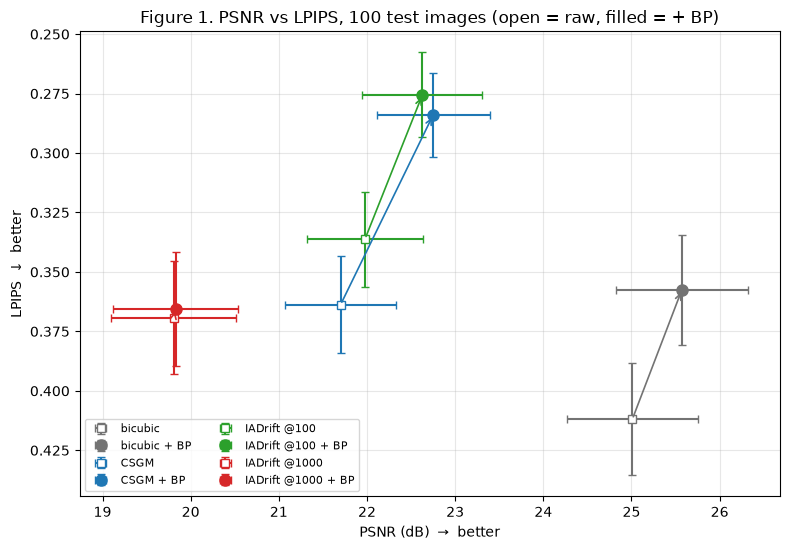

In [11]:
COLORS = {"bicubic": "0.45", "CSGM": "C0", "IADrift @100": "C2", "IADrift @1000": "C3"}
fig, ax = plt.subplots(figsize=(8, 5.6))
for base, color in COLORS.items():
    pts = {}
    for bp in (False, True):
        m = base + (" + BP" if bp else "")
        (px, ex_), (ly, ey) = mean_ci(per_image(key_of(m), "psnr")), mean_ci(per_image(key_of(m), "lpips"))
        pts[bp] = (px, ly)
        ax.errorbar(px, ly, xerr=ex_, yerr=ey, fmt="o" if bp else "s", color=color, ms=8 if bp else 6,
                    mfc=color if bp else "white", capsize=3, label=m)
    ax.annotate("", xy=pts[True], xytext=pts[False], arrowprops=dict(arrowstyle="->", color=color, lw=1.2))
ax.set(xlabel="PSNR (dB)  →  better", ylabel="LPIPS  ↓  better",
       title="Figure 1. PSNR vs LPIPS, 100 test images (open = raw, filled = + BP)")
ax.invert_yaxis()
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2, loc="lower left")
plt.tight_layout()
plt.show()

### 9.2 Primary analysis (pre-registered)

The 4 pre-registered tests: does IADrift (+ BP) beat CSGM + BP? Differences are IADrift − CSGM; for LPIPS a negative
difference means IADrift is better. The numbers are recomputed here from the per-image metrics and checked against
the values saved by the original analysis.

In [12]:
PRIMARY = [(f"IADrift @{s}, correct label + BP", "CSGM, correct label + BP", key) for s in (1000, 100) for key in ("psnr", "lpips")]
res = [paired_stats(a, b, key) for a, b, key in PRIMARY]
adj = holm(np.array([r["p"] for r in res]))
for r, pa, saved in zip(res, adj, primary_saved):
    assert np.isclose(r["mean"], saved["mean"]) and np.isclose(pa, saved["holm_p"]), "differs from the saved analysis"

lines = ["| # | Comparison | Metric | Mean difference | 95% CI | Holm-corrected p | IADrift better on |",
         "|---:|---|---|---:|---:|---:|---:|"]
for k, ((a, b, key), r, pa) in enumerate(zip(PRIMARY, res, adj), start=1):
    f = "{:+.3f}" if key == "lpips" else "{:+.2f}"
    lines.append(f"| {k} | {a.split(',')[0]} + BP − CSGM + BP | {'LPIPS ↓' if key == 'lpips' else 'PSNR (dB)'} | "
                 f"{f.format(r['mean'])} | [{f.format(r['lo'])}, {f.format(r['hi'])}] | {pa:.1e} | {r['better']}/{r['n']} images |")
display(Markdown("**Table 2. Primary tests (correct label, Holm over 4 tests).** All four are significant at 0.05.\n\n" + "\n".join(lines)))

**Table 2. Primary tests (correct label, Holm over 4 tests).** All four are significant at 0.05.

| # | Comparison | Metric | Mean difference | 95% CI | Holm-corrected p | IADrift better on |
|---:|---|---|---:|---:|---:|---:|
| 1 | IADrift @1000 + BP − CSGM + BP | PSNR (dB) | -2.92 | [-3.18, -2.66] | 1.6e-17 | 0/100 images |
| 2 | IADrift @1000 + BP − CSGM + BP | LPIPS ↓ | +0.082 | [+0.066, +0.097] | 1.0e-14 | 12/100 images |
| 3 | IADrift @100 + BP − CSGM + BP | PSNR (dB) | -0.12 | [-0.20, -0.04] | 1.4e-03 | 33/100 images |
| 4 | IADrift @100 + BP − CSGM + BP | LPIPS ↓ | -0.008 | [-0.013, -0.004] | 3.8e-05 | 72/100 images |

**Figure 2** shows the same comparison image by image: each point is one test image, the diagonal is "no difference".

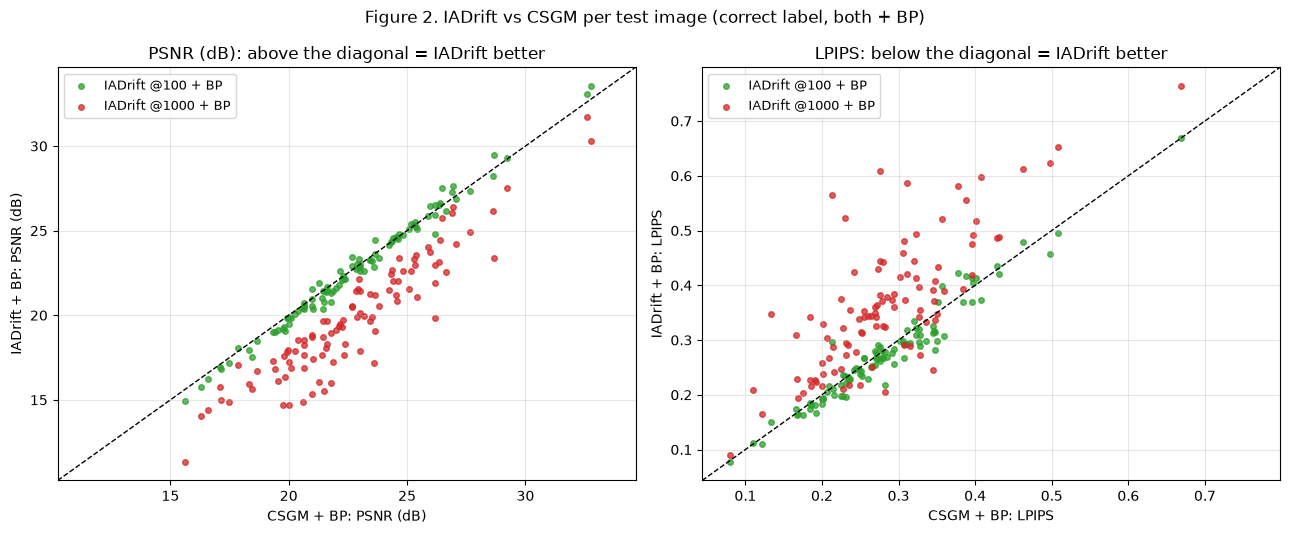

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, key, title in ((axes[0], "psnr", "PSNR (dB)"), (axes[1], "lpips", "LPIPS")):
    ref = per_image("CSGM, correct label + BP", key)
    for s, color in ((100, "C2"), (1000, "C3")):
        ax.scatter(ref, per_image(f"IADrift @{s}, correct label + BP", key), s=16, alpha=0.75, color=color,
                   label=f"IADrift @{s} + BP")
    lo, hi = min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel=f"CSGM + BP: {title}", ylabel=f"IADrift + BP: {title}",
           title=f"{title}: " + ("above the diagonal = IADrift better" if key == "psnr" else "below the diagonal = IADrift better"))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
fig.suptitle("Figure 2. IADrift vs CSGM per test image (correct label, both + BP)", fontsize=12)
plt.tight_layout()
plt.show()

### 9.3 What happens during adaptation

IADrift keeps lowering the measurement loss, but the reconstruction gets worse. **Figure 3**: left, the LR loss
$\|y - A G_\theta(\varepsilon)\|^2$ over the 1,000 adaptation steps (median and interquartile range over the 100 test
images; step 0 = the CSGM solution); middle and right, PSNR and LPIPS at step 0 (CSGM), 100 and 1,000.

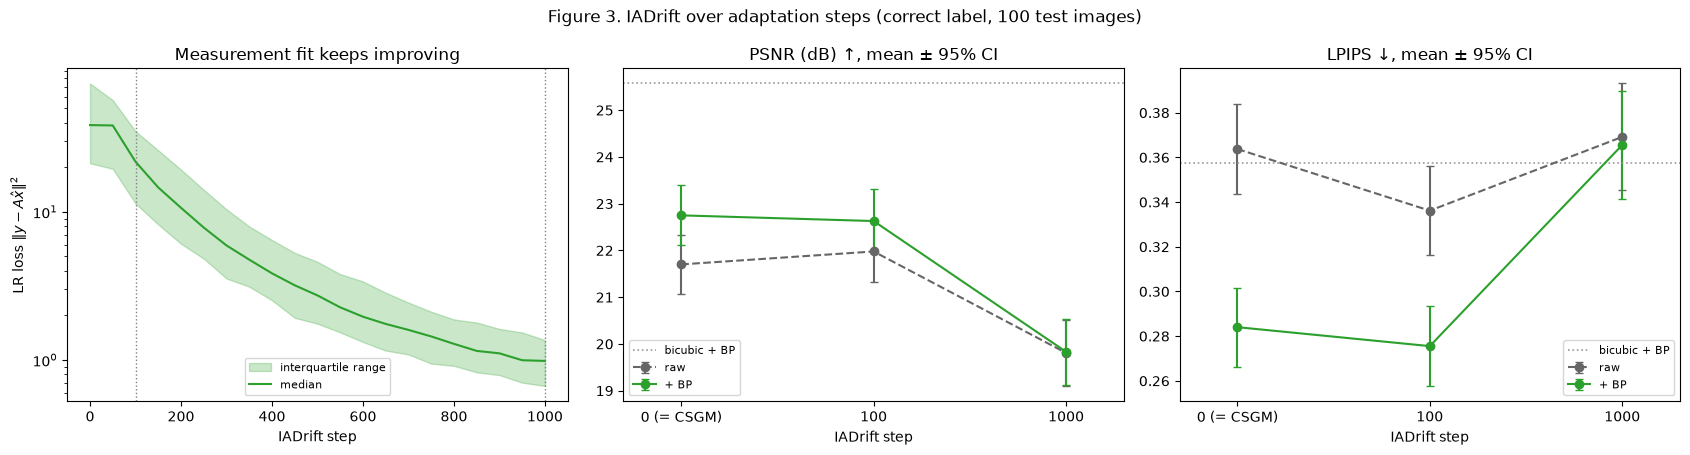

In [14]:
steps = np.concatenate([[0], traces["steps"] + 1])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
loss = np.concatenate([traces["start_loss_oracle"][:, None], traces["loss_oracle"]], axis=1)
q25, q50, q75 = np.percentile(loss, [25, 50, 75], axis=0)
axes[0].fill_between(steps, q25, q75, color="C2", alpha=0.25, label="interquartile range")
axes[0].plot(steps, q50, color="C2", label="median")
for s in IADRIFT["checkpoints"]:
    axes[0].axvline(s, color="gray", ls=":", lw=1)
axes[0].set(yscale="log", xlabel="IADrift step", ylabel="LR loss $\\|y - A\\hat x\\|^2$", title="Measurement fit keeps improving")
axes[0].legend(fontsize=8)

for ax, key, title in ((axes[1], "psnr", "PSNR (dB) ↑"), (axes[2], "lpips", "LPIPS ↓")):
    for bp, style in ((False, "--"), (True, "-")):
        names = ["CSGM", "IADrift @100", "IADrift @1000"]
        vals = [mean_ci(per_image(key_of(n + (" + BP" if bp else "")), key)) for n in names]
        ax.errorbar([0, 1, 2], [v[0] for v in vals], yerr=[v[1] for v in vals], ls=style, marker="o",
                    color="C2" if bp else "0.4", capsize=3, label="+ BP" if bp else "raw")
    ax.axhline(per_image("bicubic + BP", key).mean(), color="0.6", ls=":", lw=1.2, label="bicubic + BP")
    ax.set(xlim=(-0.3, 2.3), xlabel="IADrift step", title=f"{title}, mean ± 95% CI")
    ax.set_xticks([0, 1, 2], ["0 (= CSGM)", "100", "1000"])
    ax.legend(fontsize=8)
fig.suptitle("Figure 3. IADrift over adaptation steps (correct label, 100 test images)", fontsize=12)
plt.tight_layout()
plt.show()

### 9.4 Where the error is: frequency bands and tile seams

**Table 3** splits the error by frequency (Section 7). Bands below $f_{\text{LR}}$ are fixed by the measurement; bands above
it come only from the prior. A negative SNR means the method's content in that band is *worse than leaving it empty*
(the error is larger than the HR content itself).

**Table 3. Band SNR (dB, higher is better), correct label.** Measured bands | bands above the LR limit

| Method | low (0–0.0625) | mid (0.0625–0.125) | **high (0.125–0.25)** | **very high (> 0.25)** |
|---|---:|---:|---:|---:|
| bicubic + BP | +57.19 | +14.39 | +0.68 | -0.00 |
| CSGM + BP | +54.49 | +13.29 | -1.04 | -4.07 |
| IADrift @100 + BP | +54.41 | +13.36 | -1.06 | -4.34 |
| IADrift @1000 + BP | +52.64 | +12.51 | -2.48 | -8.18 |

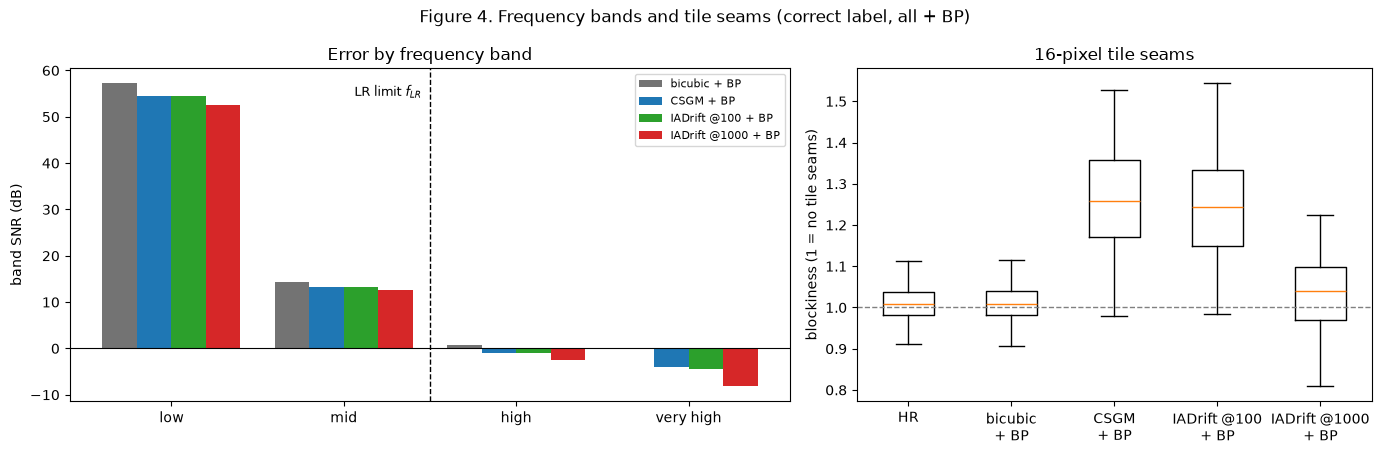

In [15]:
BANDS = ["low", "mid", "high", "very high"]
SHOW = ["bicubic + BP", "CSGM + BP", "IADrift @100 + BP", "IADrift @1000 + BP"]
lines = ["| Method | low (0–0.0625) | mid (0.0625–0.125) | **high (0.125–0.25)** | **very high (> 0.25)** |",
         "|---|---:|---:|---:|---:|"]
for m in SHOW:
    lines.append(f"| {m} | " + " | ".join(f"{per_image(key_of(m), None, b).mean():+.2f}" for b in BANDS) + " |")
display(Markdown("**Table 3. Band SNR (dB, higher is better), correct label.** Measured bands | bands above the LR limit\n\n"
                 + "\n".join(lines)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
w = 0.2
for k, m in enumerate(SHOW):
    vals = [per_image(key_of(m), None, b).mean() for b in BANDS]
    axes[0].bar(np.arange(4) + (k - 1.5) * w, vals, w, color=["0.45", "C0", "C2", "C3"][k], label=m)
axes[0].axvline(1.5, color="k", ls="--", lw=1)
axes[0].text(1.45, axes[0].get_ylim()[1] * 0.9, "LR limit $f_{LR}$", ha="right", fontsize=9)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xticks(range(4), BANDS)
axes[0].set(ylabel="band SNR (dB)", title="Error by frequency band")
axes[0].legend(fontsize=8)

hr_b = np.array([metrics[str(i)]["hr_blockiness"] for i in images])
axes[1].boxplot([hr_b] + [per_image(key_of(m), "blockiness") for m in SHOW], showfliers=False,
                tick_labels=["HR"] + [m.replace(" + BP", "\n+ BP") for m in SHOW])
axes[1].axhline(1.0, color="gray", ls="--", lw=1)
axes[1].set(ylabel="blockiness (1 = no tile seams)", title="16-pixel tile seams")
fig.suptitle("Figure 4. Frequency bands and tile seams (correct label, all + BP)", fontsize=12)
plt.tight_layout()
plt.show()

### 9.5 Visual examples

The **first 4 images of the fixed test sample** (not chosen by result). Top: full images; bottom: an $80\times80$
detail crop (yellow box), chosen automatically as the HR region with the most edges. Titles give PSNR / LPIPS.

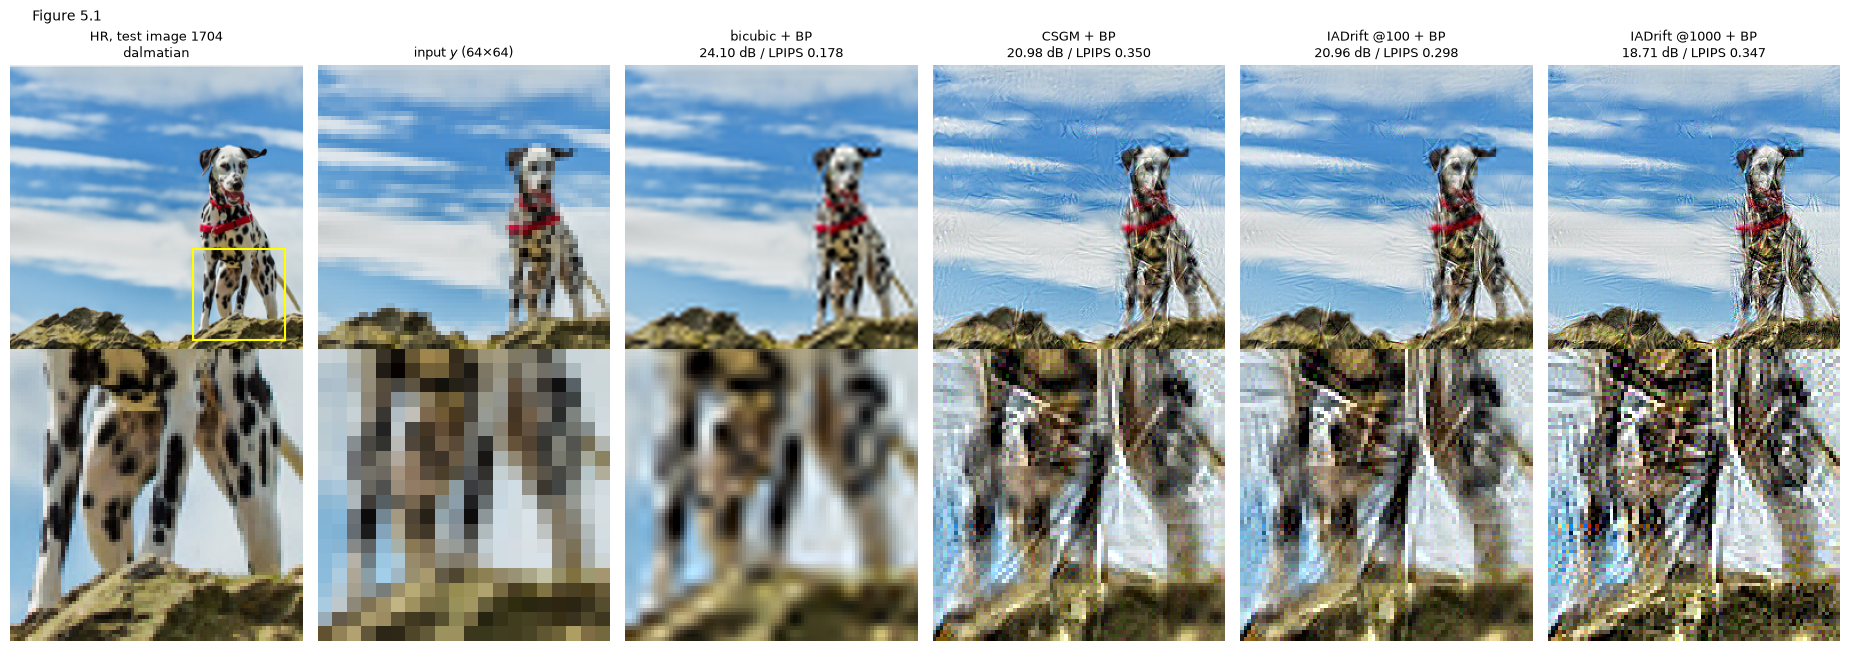

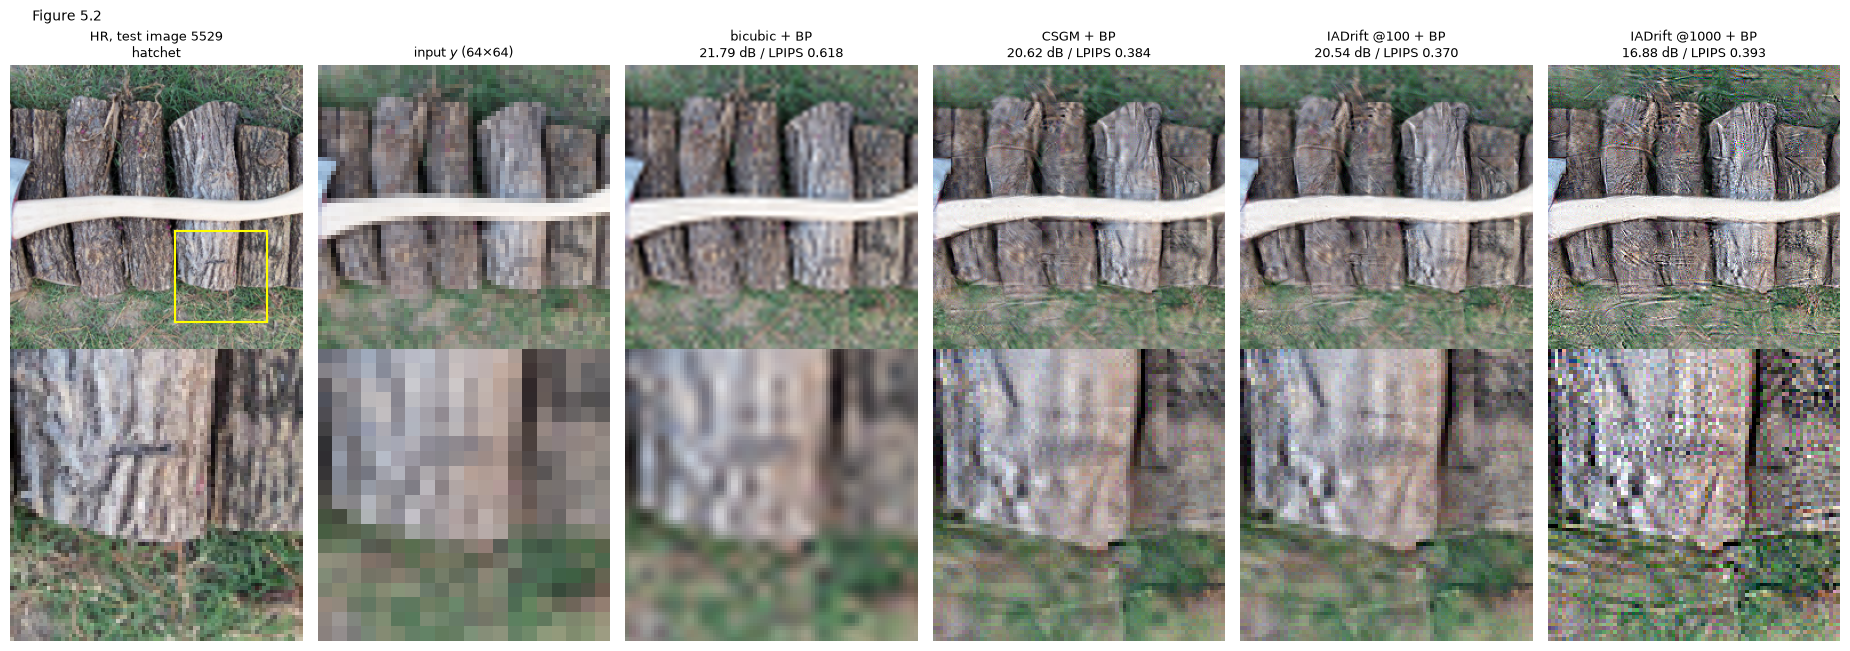

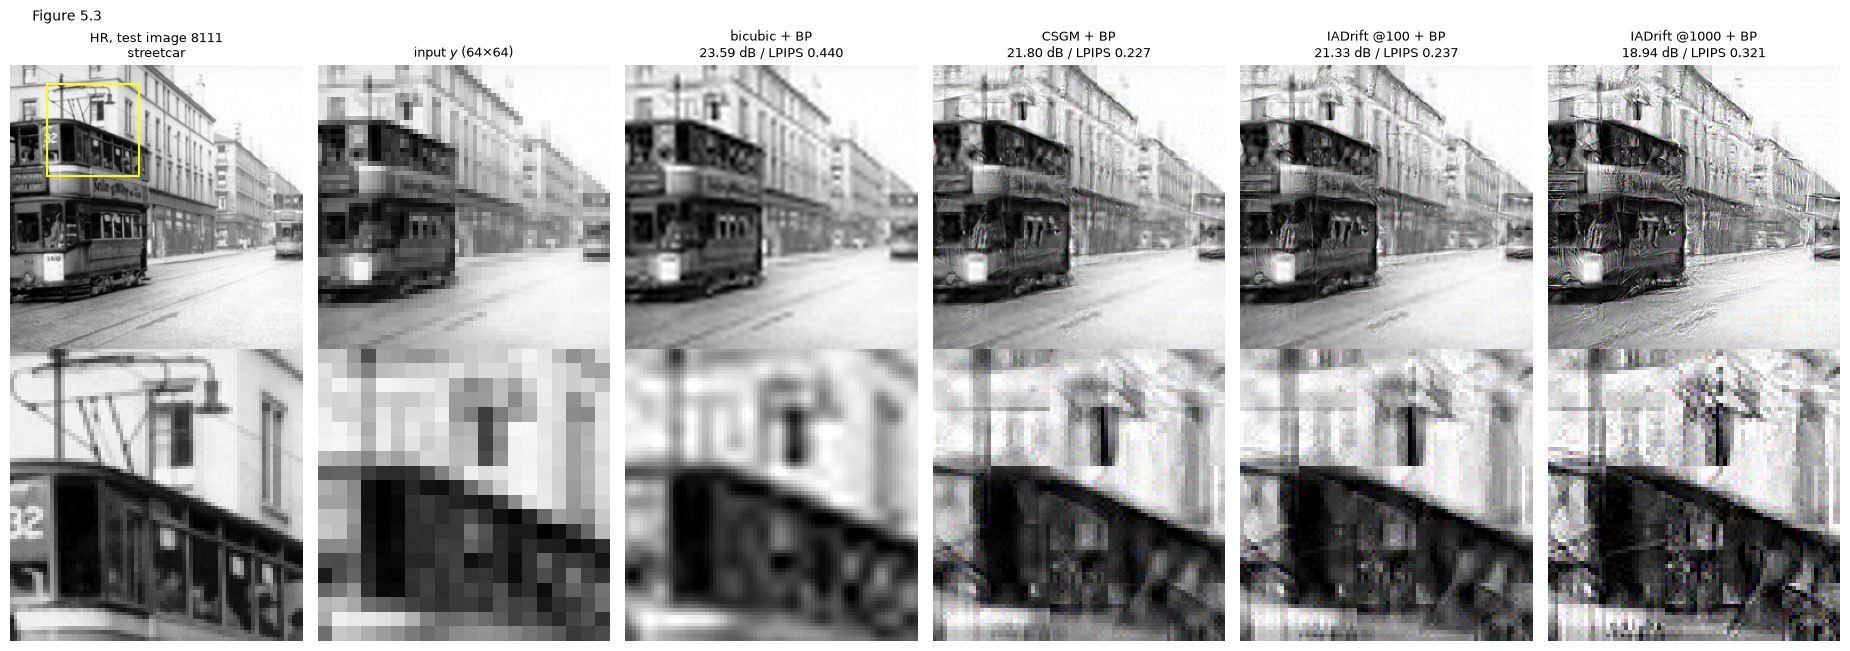

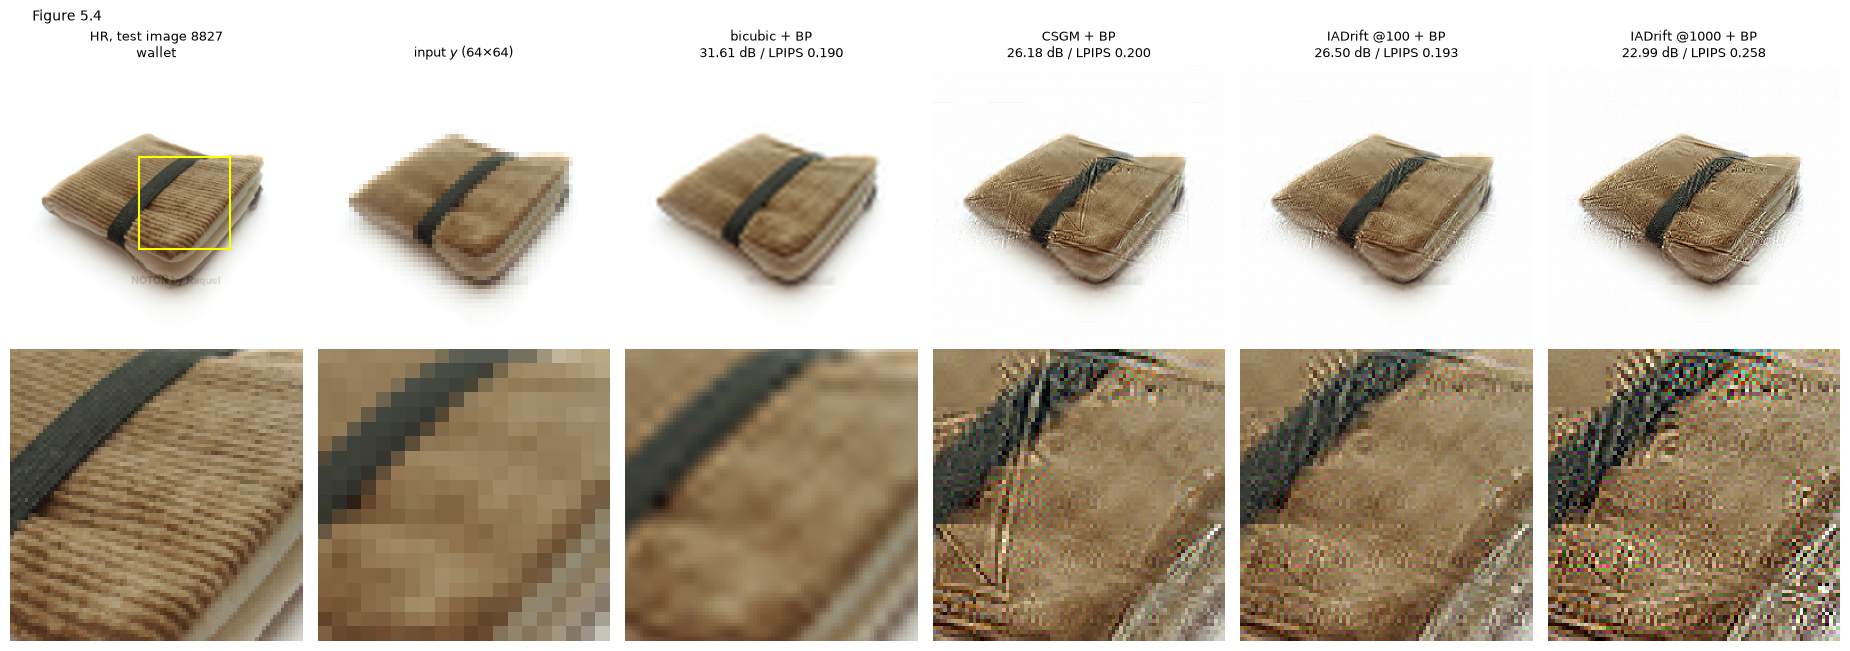

In [16]:
CROP = 80


def detail_crop(hr):
    g = np.abs(np.diff(hr.mean(-1), axis=0))[:, :-1] + np.abs(np.diff(hr.mean(-1), axis=1))[:-1, :]
    pos = [(r, c) for r in range(0, 256 - CROP, 16) for c in range(0, 256 - CROP, 16)]
    return max(pos, key=lambda p: g[p[0]:p[0] + CROP, p[1]:p[1] + CROP].sum())


PANELS = ["bicubic + BP", "CSGM + BP", "IADrift @100 + BP", "IADrift @1000 + BP"]
for n, ex in enumerate(examples):
    i, hr = sample[n]["image_index"], ex["hr"]
    r, c = detail_crop(hr)
    fig, axes = plt.subplots(2, len(PANELS) + 2, figsize=(3.1 * (len(PANELS) + 2), 6.6))
    axes[0, 0].imshow(show(hr))
    axes[0, 0].add_patch(plt.Rectangle((c, r), CROP, CROP, fill=False, color="yellow", lw=1.5))
    axes[0, 0].set_title(f"HR, test image {i}\n{sample[n]['true_class']}", fontsize=9)
    axes[1, 0].imshow(show(hr[r:r + CROP, c:c + CROP]), interpolation="nearest")
    axes[0, 1].imshow(show(ex["lr"]), interpolation="nearest")
    axes[0, 1].set_title("input $y$ (64×64)", fontsize=9)
    axes[1, 1].imshow(show(ex["lr"][r // 4:(r + CROP) // 4, c // 4:(c + CROP) // 4]), interpolation="nearest")
    for k, m in enumerate(PANELS, start=2):
        x, mm = ex[key_of(m)], metrics[str(i)][key_of(m)]
        axes[0, k].imshow(show(x))
        axes[0, k].set_title(f"{m}\n{mm['psnr']:.2f} dB / LPIPS {mm['lpips']:.3f}", fontsize=9)
        axes[1, k].imshow(show(x[r:r + CROP, c:c + CROP]), interpolation="nearest")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(f"Figure 5.{n + 1}", fontsize=10, x=0.02, ha="left")
    plt.tight_layout()
    plt.show()

### 9.6 Secondary: the class label

The same pipeline with a random **wrong** class label (exploratory, uncorrected tests).

In [17]:
display(Markdown("**Table 4. Wrong class label, 100 test images.**\n\n" + main_table("wrong label")))
lines = ["| Method | PSNR: correct − wrong (dB) | 95% CI | LPIPS: correct − wrong | 95% CI | p (LPIPS) |",
         "|---|---:|---:|---:|---:|---:|"]
for m in ["CSGM", "CSGM + BP", "IADrift @100 + BP", "IADrift @1000 + BP"]:
    a, b = key_of(m, "correct label"), key_of(m, "wrong label")
    rp, rl = paired_stats(a, b, "psnr"), paired_stats(a, b, "lpips")
    lines.append(f"| {m} | {rp['mean']:+.2f} | [{rp['lo']:+.2f}, {rp['hi']:+.2f}] | {rl['mean']:+.3f} | "
                 f"[{rl['lo']:+.3f}, {rl['hi']:+.3f}] | {rl['p']:.2g} |")
display(Markdown("**Table 5. Effect of the correct label (paired, exploratory).**\n\n" + "\n".join(lines)))

**Table 4. Wrong class label, 100 test images.**

| Method | PSNR (dB) ↑ | PSNR of mean MSE (dB) ↑ | LPIPS ↓ | Blockiness (HR = 1.01) |
|---|---:|---:|---:|---:|
| bicubic | 25.01 | 23.61 | 0.412 | 1.01 |
| bicubic + BP | **25.57** | **24.14** | 0.358 | 1.01 |
| CSGM | 21.68 | 20.67 | 0.391 | 1.46 |
| CSGM + BP | 22.81 | 21.72 | 0.302 | 1.32 |
| IADrift @100 | 21.99 | 20.88 | 0.361 | 1.40 |
| IADrift @100 + BP | 22.74 | 21.51 | **0.291** | 1.29 |
| IADrift @1000 | 19.61 | 18.42 | 0.397 | 1.07 |
| IADrift @1000 + BP | 19.64 | 18.44 | 0.394 | 1.06 |

**Table 5. Effect of the correct label (paired, exploratory).**

| Method | PSNR: correct − wrong (dB) | 95% CI | LPIPS: correct − wrong | 95% CI | p (LPIPS) |
|---|---:|---:|---:|---:|---:|
| CSGM | +0.02 | [-0.24, +0.28] | -0.028 | [-0.044, -0.012] | 0.0029 |
| CSGM + BP | -0.06 | [-0.34, +0.22] | -0.018 | [-0.032, -0.004] | 0.03 |
| IADrift @100 + BP | -0.11 | [-0.38, +0.17] | -0.015 | [-0.029, -0.001] | 0.09 |
| IADrift @1000 + BP | +0.19 | [-0.13, +0.52] | -0.028 | [-0.046, -0.010] | 0.017 |

## 10. Summary

1. **CSGM with a drift prior is below bicubic on PSNR but better on LPIPS** (Table 1, Figure 1): CSGM + BP is about
   2.8 dB below bicubic + BP, yet clearly closer perceptually. The two metrics disagree because the prior adds plausible
   but not pixel-exact detail.
2. **Back-projection helps every method** (Figure 1 arrows) at no cost: it removes the part of each reconstruction that
   contradicts the measurement.
3. **IAGAN-style adaptation doesn't help with this generator** (Table 2, Figures 2–3): after 1,000 steps IADrift + BP is about 2.9 dB
   worse than CSGM + BP on every image and worse on LPIPS; early-stopped (100 steps) it is essentially tied
   (−0.12 dB PSNR, −0.008 LPIPS).
4. **Why:** adaptation keeps lowering the measurement loss (Figure 3, left) while the image gets worse. The extra freedom
   is spent above the LR limit, where the measurement barely constrains it (Table 3: the very-high band gets much worse). It also
   removes the tile seams (Figure 4), so the generator's 16-pixel patch grid is not the main source of error.
5. **The class label** doesn't change PSNR (Table 5: differences within ±0.2 dB, CIs include 0) but the correct label
   gives slightly better LPIPS (−0.02 to −0.03; exploratory, uncorrected).

The next notebooks examine *why* in more detail (development experiments) and what does help on the test set
(averaging several reconstructions).